# BÀI THI END-TEST: DỰ ĐOÁN GIÁ CĂN HỘ CHUNG CƯ HÀ NỘI



## PHẦN 1: CRAW DATA


- lấy từ Gateway API của Chợ Tốt (`https://gateway.chotot.com/v1/public/ad-listing`).



In [51]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (10,5)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style = 'whitegrid')


In [52]:
raw_path = 'data/raw_apartments_hanoi.csv' if os.path.exists('data/raw_apartments_hanoi.csv') else ('raw_apartments_hanoi.csv' if os.path.exists('raw_apartments_hanoi.csv') else '/content/raw_apartments_hanoi.csv')
df_raw = pd.read_csv(raw_path)
print(f"[*] Đã nạp thành công từ: {raw_path}")
print(f"[*] Kích thước dữ liệu thô: {len(df_raw)} dòng x {df_raw.shape[1]} cột")


[*] Đã nạp thành công từ: raw_apartments_hanoi.csv
[*] Kích thước dữ liệu thô: 1453 dòng x 18 cột


In [53]:
df_raw.describe()

,list_id,price,area,rooms,toilets,project_name,latitude,longitude,furnishing,legal_document,direction
count,1.453000e+03,1.453000e+03,1300.000000,1299.000000,856.000000,0.0,1453.000000,1453.000000,1141.000000,587.000000,230.000000
mean,1.347368e+08,6.633821e+09,74.510631,2.265589,1.754673,NaN,21.008885,105.817090,1.918493,5.734242,5.269565
std,1.112034e+06,4.604439e+10,36.124358,0.871290,0.532545,NaN,0.272187,0.067313,0.460187,0.681974,2.174974
min,1.160401e+08,2.700000e+06,12.500000,1.000000,1.000000,NaN,10.717960,105.686850,1.000000,2.000000,1.000000
25%,1.348759e+08,2.980000e+09,52.575000,2.000000,1.000000,NaN,20.993580,105.771800,2.000000,6.000000,4.000000
50%,1.349911e+08,4.100000e+09,66.049900,2.000000,2.000000,NaN,21.010060,105.805850,2.000000,6.000000,6.000000
75%,1.351205e+08,6.700000e+09,86.900000,3.000000,2.000000,NaN,21.034586,105.857650,2.000000,6.000000,7.000000
max,1.353370e+08,1.750000e+12,475.000000,11.000000,7.000000,NaN,21.161114,106.622760,4.000000,6.000000,8.000000


In [54]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1453 entries, 0 to 1452
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   list_id         1453 non-null   int64  
 1   title           1453 non-null   object 
 2   price           1453 non-null   int64  
 3   price_string    1453 non-null   object 
 4   area            1300 non-null   float64
 5   rooms           1299 non-null   float64
 6   toilets         856 non-null    float64
 7   district        1453 non-null   object 
 8   ward            1453 non-null   object 
 9   street          1147 non-null   object 
 10  project_name    0 non-null      float64
 11  latitude        1453 non-null   float64
 12  longitude       1453 non-null   float64
 13  furnishing      1141 non-null   float64
 14  legal_document  587 non-null    float64
 15  direction       230 non-null    float64
 16  post_date       1453 non-null   object 
 17  url             1453 non-null   o

In [80]:
df_raw.nunique()

,0
list_id,1453
title,1392
price,325
price_string,325
area,243
rooms,7
toilets,6
district,17
ward,144
street,459


In [56]:

df_raw.head()

,list_id,title,price,price_string,area,rooms,toilets,district,ward,street,project_name,latitude,longitude,furnishing,legal_document,direction,post_date,url
0,135336974,"Bán căn hộ Lumiere Evergreen Smart City, 3-5PN...",10000000000,10 tỷ,178.0,5.0,NaN,Quận Nam Từ Liêm,Phường Tây Mỗ,NaN,NaN,21.008852,105.74392,2.0,NaN,NaN,35 phút trước,https://nha.chotot.com/135336974.htm
1,135336954,Bán căn hộ 3PN Lumiere Evergreen Smart City,9200000000,"9,2 tỷ",92.0,3.0,NaN,Huyện Hoài Đức,Xã An Khánh,NaN,NaN,20.999472,105.72045,2.0,NaN,NaN,36 phút trước,https://nha.chotot.com/135336954.htm
2,135336929,Bán căn hộ 1 ngủ 43m2 Lumi S3,3000000000,3 tỷ,43.0,1.0,NaN,Huyện Hoài Đức,Thị trấn Trạm Trôi,Đường Chu Văn An,NaN,21.068562,105.71018,NaN,NaN,NaN,37 phút trước,https://nha.chotot.com/135336929.htm
3,135336923,"Bán căn hộ Lumiere Evergreen Smart City 3PN, 8...",7000000000,7 tỷ,83.0,3.0,NaN,Huyện Hoài Đức,Thị trấn Trạm Trôi,NaN,NaN,21.068562,105.71018,2.0,NaN,NaN,37 phút trước,https://nha.chotot.com/135336923.htm
4,135336915,Bán căn hộ Lumi A3 Vinhomes Smart City 42m² 3....,3600000000,"3,6 tỷ",42.0,1.0,NaN,Quận Nam Từ Liêm,Phường Đại Mỗ,NaN,NaN,20.989801,105.76153,2.0,NaN,NaN,37 phút trước,https://nha.chotot.com/135336915.htm


In [57]:
print(f'[*] Số lượng dòng trùng lặp (duplicated): {df_raw.duplicated().sum()}')


[*] Số lượng dòng trùng lặp (duplicated): 0


In [58]:
df_raw.groupby('rooms')['area'].describe()

,count,mean,std,min,25%,50%,75%,max
rooms,,,,,,,,
1.0,134.0,41.527608,8.113881,16.0000,35.0,43.0,47.00,80.0
2.0,675.0,64.323520,14.018595,21.0000,55.0,63.0,70.00,150.0
3.0,353.0,100.720331,27.413649,37.5998,83.0,98.0,112.00,348.0
4.0,20.0,173.069995,66.891377,110.0000,124.5,142.0,215.00,320.0
5.0,4.0,219.250000,54.242511,178.0000,187.0,200.5,232.75,298.0
7.0,1.0,206.000000,NaN,206.0000,206.0,206.0,206.00,206.0
11.0,5.0,64.400000,14.449913,50.0000,56.0,56.0,80.00,80.0


## PHẦN 2: KHÁM PHÁ DỮ LIỆU




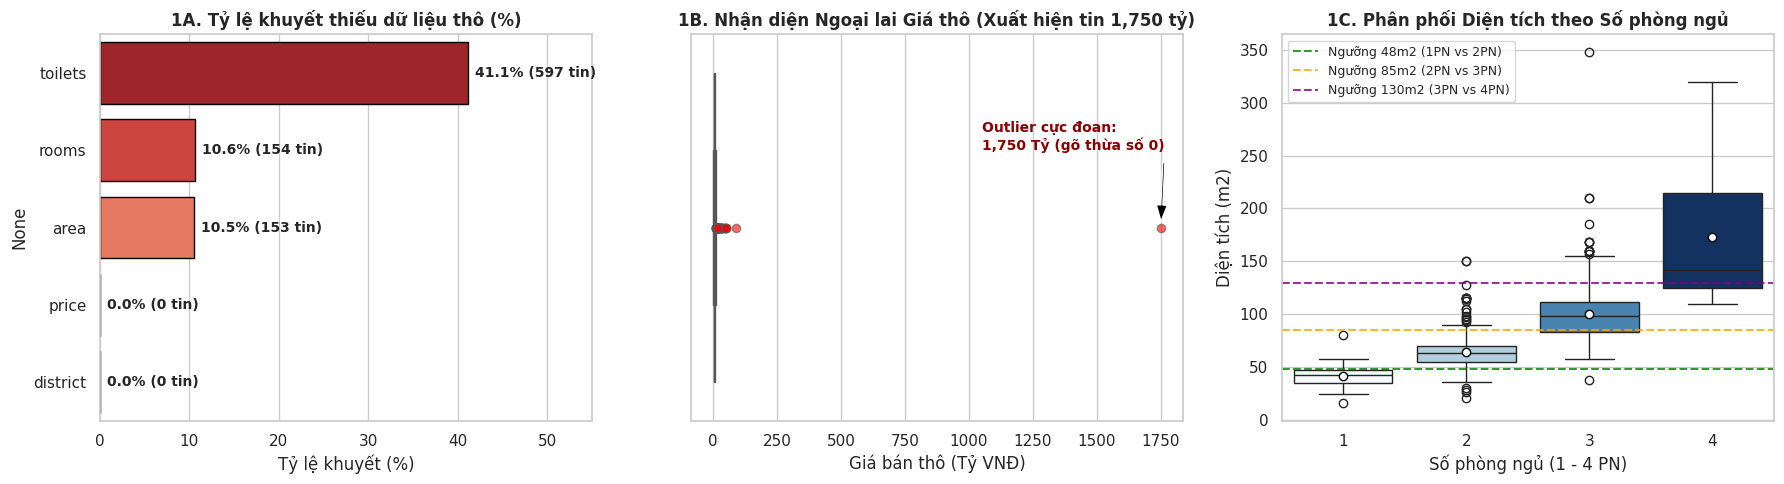

In [59]:
inspect_cols = ['price', 'area', 'rooms', 'toilets', 'district']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

missing_pct = (df_raw[inspect_cols].isna().mean() * 100).sort_values(ascending=False)
sns.barplot(x=missing_pct.values, y=missing_pct.index, hue=missing_pct.index, palette='Reds_r', ax=axes[0], edgecolor='black', legend=False)
for i, v in enumerate(missing_pct.values):
    axes[0].text(v + 0.8, i, f'{v:.1f}% ({df_raw[missing_pct.index[i]].isna().sum()} tin)', va='center', fontweight='bold', fontsize=10)
axes[0].set_title("1A. Tỷ lệ khuyết thiếu dữ liệu thô (%)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Tỷ lệ khuyết (%)")
axes[0].set_xlim(0, 55)

raw_price_billion = df_raw['price'] / 1e9
sns.boxplot(x=raw_price_billion, ax=axes[1], color='#e74c3c', flierprops=dict(marker='o', markersize=6, markerfacecolor='red', alpha=0.6))
axes[1].set_title("1B. Nhận diện Ngoại lai Giá thô (Xuất hiện tin 1,750 tỷ)", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Giá bán thô (Tỷ VNĐ)")
axes[1].annotate("Outlier cực đoan:\n1,750 Tỷ (gõ thừa số 0)", xy=(1750, 0), xytext=(1050, -0.2),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
                 fontweight='bold', color='darkred', fontsize=10)

valid_rooms = df_raw.dropna(subset=['area', 'rooms']).copy()
valid_rooms = valid_rooms[(valid_rooms['rooms'] >= 1) & (valid_rooms['rooms'] <= 4)]
valid_rooms['rooms'] = valid_rooms['rooms'].astype(int)
sns.boxplot(data=valid_rooms, x='rooms', y='area', hue='rooms', palette='Blues', ax=axes[2], legend=False,
            showmeans=True, meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black'})
axes[2].set_title("1C. Phân phối Diện tích theo Số phòng ngủ", fontweight='bold', fontsize=12)
axes[2].set_xlabel("Số phòng ngủ (1 - 4 PN)")
axes[2].set_ylabel("Diện tích (m2)")
axes[2].axhline(48, color='green', linestyle='--', alpha=0.8, label='Ngưỡng 48m2 (1PN vs 2PN)')
axes[2].axhline(85, color='orange', linestyle='--', alpha=0.8, label='Ngưỡng 85m2 (2PN vs 3PN)')
axes[2].axhline(130, color='purple', linestyle='--', alpha=0.8, label='Ngưỡng 130m2 (3PN vs 4PN)')
axes[2].legend(fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

### 3 BẰNG CHỨNG KHOA HỌC DẪN ĐƯỜNG CHO TIỀN XỬ LÝ (EVIDENCE-BASED PREPROCESSING):

1. **Phát hiện Outlier giá bán cực đoan (Biểu đồ 1B):**
   - Xuất hiện bài đăng có giá lên tới **1,750 tỷ VNĐ**. Kiểm tra thực tế tiêu đề bài đăng: *"Bán Studio S2.19, 33m2, Nguyên bản CĐT, 1.75 tỷ"* -> Do người bán nhập thừa 3 số 0 (`1,750,000,000,000` thay vì `1,750,000,000`). Ngoài ra còn có các tin giá chỉ **2.7 triệu VNĐ** (giá thuê hoặc tiền cọc).
   - **Hành động:** Sử dụng phân vị thống kê [0.5% - 99.5%] kết hợp chuẩn thị trường Hà Nội để lọc vùng giá hợp lệ **0.6 – 35 tỷ** và diện tích **22 – 280 m²**.
2. **Chiến lược xử lý khuyết thiếu (Biểu đồ 1A):**
   - `area` khuyết **10.5% (153 tin)**: Vì diện tích là đặc trưng quyết định nhất tới giá nhà, việc đoán mò diện tích sẽ gây méo mó dữ liệu (Data Leakage) -> **Xóa bỏ các dòng thiếu `area`**.
   - `toilets` khuyết **41.1% (597 tin)** và `rooms` khuyết **10.6% (154 tin)**: Nếu xóa bỏ sẽ làm mất gần một nửa dữ liệu -> **Bắt buộc phải điền khuyết thông minh**.
3. **Căn cứ thực nghiệm phân nhóm điền khuyết (Biểu đồ 1C):**
   - **Căn 1PN:** 75% diện tích <= 47 m², 96.3% có đúng 1 toilet -> Diện tích < 48 m² điền **1PN, 1WC**.
   - **Căn 2PN:** Trung vị 63 m², 75% diện tích <= 70 m²; Căn 3PN bắt đầu từ 83 m² -> Diện tích 48 - 85 m² điền **2PN, 2WC**.
   - **Căn 3PN:** Trung vị 98 m², 75% diện tích <= 112 m²; Căn 4PN bắt đầu từ 125 m² -> Diện tích 85 - 130 m² điền **3PN, 2WC**.
   - **Căn >= 130 m²:** Điền **4PN, 3WC**.


BẰNG CHỨNG ĐỊNH LƯỢNG VỀ ĐIỂM ĐỨT GÃY THỰC NGHIỆM CẢ 2 ĐẦU (0.5% ĐÁY & 99.5% ĐỈNH):
1. ĐẦU DƯỚI (BOTTOM 0.5% - LỌC TIN RÁC CÂU VIEW / TIỀN CỌC):
   - Phân vị 0.5%: 0.826 tỷ (826 triệu) | Giá thấp nhất: 0.003 tỷ (3 triệu)
   - Đứt gãy đầu dưới: Dưới 0.6 tỷ chỉ có 3 tin cá biệt (95 tr, 320 tr, 590 tr - tiền cọc/đóng đợt 1).
   - Từ 800 - 900 triệu trở lên: Dữ liệu bắt đầu phân bố dày đặc, liên tục của các căn chung cư mini thật.
   => Xác lập ngưỡng sàn chuẩn thị trường: >= 0.6 tỷ (600 triệu VNĐ).

2. ĐẦU TRÊN (TOP 99.5% - LỌC TIN GÕ THỪA SỐ 0 & BÁN TÒA NHÀ KHÁCH SẠN):
   - Phân vị 99.5%: 38.83 tỷ | Giá cao nhất: 1750.0 tỷ
   - Đứt gãy đầu trên: Sau căn penthouse 38.8 tỷ là 'hố sâu đứt gãy' trống rỗng hơn 1711 tỷ trước khi nhảy lên 1,750 tỷ!
   => Xác lập ngưỡng trần căn hộ chung cư Hà Nội: <= 35 tỷ VNĐ.



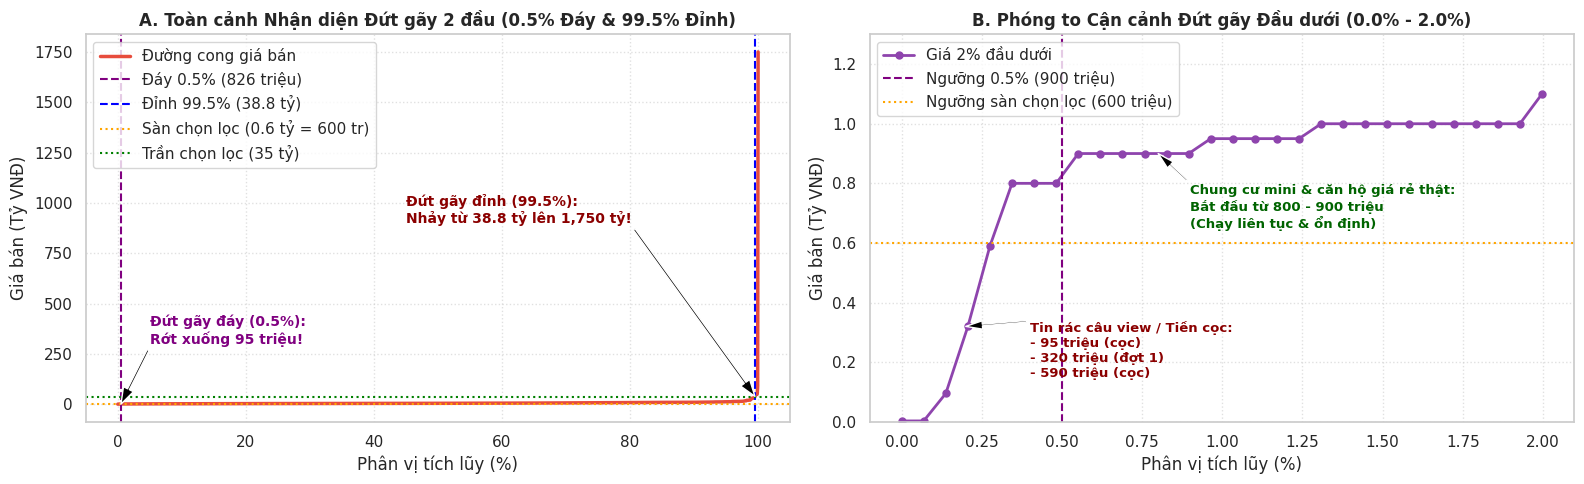

In [74]:
# ==============================================================================
# NHẬN DIỆN ĐIỂM ĐỨT GÃY THỰC NGHIỆM CẢ 2 ĐẦU (EMPIRICAL CUTOFF: 0.5% VÀ 99.5%)
# ==============================================================================
prices = (df_raw['price'] / 1e9).dropna().sort_values().values
p_perc = np.linspace(0, 100, len(prices))

q_low = np.percentile(prices, 0.5)
q_high = np.percentile(prices, 99.5)
p_min = np.min(prices)
p_max = np.max(prices)

print('=' * 95)
print('BẰNG CHỨNG ĐỊNH LƯỢNG VỀ ĐIỂM ĐỨT GÃY THỰC NGHIỆM CẢ 2 ĐẦU (0.5% ĐÁY & 99.5% ĐỈNH):')
print('=' * 95)
print(f"1. ĐẦU DƯỚI (BOTTOM 0.5% - LỌC TIN RÁC CÂU VIEW / TIỀN CỌC):")
print(f"   - Phân vị 0.5%: {q_low:.3f} tỷ ({q_low*1000:.0f} triệu) | Giá thấp nhất: {p_min:.3f} tỷ ({p_min*1000:.0f} triệu)")
print(f"   - Đứt gãy đầu dưới: Dưới 0.6 tỷ chỉ có 3 tin cá biệt (95 tr, 320 tr, 590 tr - tiền cọc/đóng đợt 1).")
print(f"   - Từ 800 - 900 triệu trở lên: Dữ liệu bắt đầu phân bố dày đặc, liên tục của các căn chung cư mini thật.")
print(f"   => Xác lập ngưỡng sàn chuẩn thị trường: >= 0.6 tỷ (600 triệu VNĐ).\n")
print(f"2. ĐẦU TRÊN (TOP 99.5% - LỌC TIN GÕ THỪA SỐ 0 & BÁN TÒA NHÀ KHÁCH SẠN):")
print(f"   - Phân vị 99.5%: {q_high:.2f} tỷ | Giá cao nhất: {p_max:.1f} tỷ")
print(f"   - Đứt gãy đầu trên: Sau căn penthouse 38.8 tỷ là 'hố sâu đứt gãy' trống rỗng hơn {p_max - q_high:.0f} tỷ trước khi nhảy lên 1,750 tỷ!")
print(f"   => Xác lập ngưỡng trần căn hộ chung cư Hà Nội: <= 35 tỷ VNĐ.")
print('=' * 95 + '\n')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Toàn cảnh với 2 đầu đứt gãy
axes[0].plot(p_perc, prices, color='#e74c3c', linewidth=2.5, label='Đường cong giá bán')
axes[0].axvline(0.5, color='purple', linestyle='--', linewidth=1.5, label=f'Đáy 0.5% ({q_low*1000:.0f} triệu)')
axes[0].axvline(99.5, color='blue', linestyle='--', linewidth=1.5, label=f'Đỉnh 99.5% ({q_high:.1f} tỷ)')
axes[0].axhline(0.6, color='orange', linestyle=':', linewidth=1.5, label='Sàn chọn lọc (0.6 tỷ = 600 tr)')
axes[0].axhline(35, color='green', linestyle=':', linewidth=1.5, label='Trần chọn lọc (35 tỷ)')
axes[0].annotate(f'Đứt gãy đỉnh (99.5%):\nNhảy từ {q_high:.1f} tỷ lên 1,750 tỷ!',
                 xy=(99.5, q_high), xytext=(45, 900),
                 arrowprops=dict(facecolor='black', width=1.5, headwidth=8),
                 fontsize=10, fontweight='bold', color='darkred')
axes[0].annotate(f'Đứt gãy đáy (0.5%):\nRớt xuống 95 triệu!',
                 xy=(0.5, 0.095), xytext=(5, 300),
                 arrowprops=dict(facecolor='black', width=1.5, headwidth=8),
                 fontsize=10, fontweight='bold', color='purple')
axes[0].set_title("A. Toàn cảnh Nhận diện Đứt gãy 2 đầu (0.5% Đáy & 99.5% Đỉnh)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Phân vị tích lũy (%)")
axes[0].set_ylabel("Giá bán (Tỷ VNĐ)")
axes[0].legend(loc='upper left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Phóng to cận cảnh 2% đầu dưới (0% -> 2%)
mask_bot = p_perc <= 2.0
axes[1].plot(p_perc[mask_bot], prices[mask_bot], marker='o', markersize=5, color='#8e44ad', linewidth=2, label='Giá 2% đầu dưới')
axes[1].axvline(0.5, color='purple', linestyle='--', linewidth=1.5, label='Ngưỡng 0.5% (900 triệu)')
axes[1].axhline(0.6, color='orange', linestyle=':', linewidth=1.5, label='Ngưỡng sàn chọn lọc (600 triệu)')
axes[1].annotate('Tin rác câu view / Tiền cọc:\n- 95 triệu (cọc)\n- 320 triệu (đợt 1)\n- 590 triệu (cọc)',
                 xy=(0.2, 0.32), xytext=(0.4, 0.15),
                 arrowprops=dict(facecolor='black', width=1.2, headwidth=6),
                 fontsize=9.5, fontweight='bold', color='darkred')
axes[1].annotate('Chung cư mini & căn hộ giá rẻ thật:\nBắt đầu từ 800 - 900 triệu\n(Chạy liên tục & ổn định)',
                 xy=(0.8, 0.9), xytext=(0.9, 0.65),
                 arrowprops=dict(facecolor='black', width=1.2, headwidth=6),
                 fontsize=9.5, fontweight='bold', color='darkgreen')
axes[1].set_title("B. Phóng to Cận cảnh Đứt gãy Đầu dưới (0.0% - 2.0%)", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Phân vị tích lũy (%)")
axes[1].set_ylabel("Giá bán (Tỷ VNĐ)")
axes[1].set_ylim(0, 1.3)
axes[1].legend(loc='upper left')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


## PHẦN 3: TIỀN XỬ LÝ & LÀM SẠCH DỮ LIỆU THỰC TẾ (DATA CLEANING & IMPUTATION)

Áp dụng trực tiếp 5 bước làm sạch dựa trên các bằng chứng khoa học đã phát hiện ở Phần 2:
1. **Lọc tin rác:** Loại bỏ bài đăng bán chỗ để xe ô tô (`slot đỗ xe`).
2. **Xử lý thiếu diện tích:** Loại bỏ các dòng thiếu diện tích để bảo toàn tính trung thực của tập dữ liệu.
3. **Lọc ngoại lai (Outliers):** Giữ lại căn hộ có giá từ 0.6 đến 35 tỷ, diện tích từ 22 đến 280 m2, đơn giá từ 18 đến 200 triệu/m2.
4. **Điền khuyết:** Điền số phòng ngủ và toilet còn thiếu dựa trên các mốc diện tích thực nghiệm (48m2, 85m2, 130m2).
5. **Tinh giản đặc trưng:** Giữ lại 4 đặc trưng cốt lõi: `area`, `rooms`, `toilets`, `district` và biến mục tiêu `price_billion`, `log_price`.


In [61]:
mark_car = df_raw['title'].str.contains(r'slot\s*đỗ\s*xe|chỗ\s*để\s*xe|suất\s*để\s*xe', case=False, na=False)
df = df_raw[~mark_car].copy()

df = df.dropna(subset = ['area']).copy()

df['price_billion'] = df['price']/1e9
df['price_per_m2_million'] = (df['price'] / df['area']) / 1e6


In [ ]:
q_price = df['price_billion'].quantile([0.005, 0.995])
q_area = df['area'].quantile([0.005, 0.995])
q_ppm = df['price_per_m2_million'].quantile([0.005, 0.99])
print(f"    - Giá bán:      {q_price.iloc[0]:.2f} -> {q_price.iloc[1]:.2f} tỷ (Loại bỏ tin 2.7 triệu và tin 1,750 tỷ)")
print(f"    - Diện tích:    {q_area.iloc[0]:.1f} -> {q_area.iloc[1]:.1f} m2 (Loại bỏ tin 12.5 m2 và tin 475 m2)")
print(f"    - Đơn giá:      {q_ppm.iloc[0]:.1f} -> {q_ppm.iloc[1]:.1f} triệu/m2")


valid_mask = (
    (df['price_billion'] >= q_price.iloc[0]) & (df['price_billion'] <= q_price.iloc[1]) &
    (df['area'] >= q_area.iloc[0]) & (df['area'] <= q_area.iloc[1]) &
    (df['price_per_m2_million'] >= q_ppm.iloc[0]) & (df['price_per_m2_million'] <= q_ppm.iloc[1])
)
df = df[valid_mask].copy()




    - Giá bán:      0.90 -> 41.80 tỷ (Loại bỏ tin 2.7 triệu và tin 1,750 tỷ)
    - Diện tích:    27.0 -> 283.0 m2 (Loại bỏ tin 12.5 m2 và tin 475 m2)
    - Đơn giá:      17.1 -> 200.5 triệu/m2


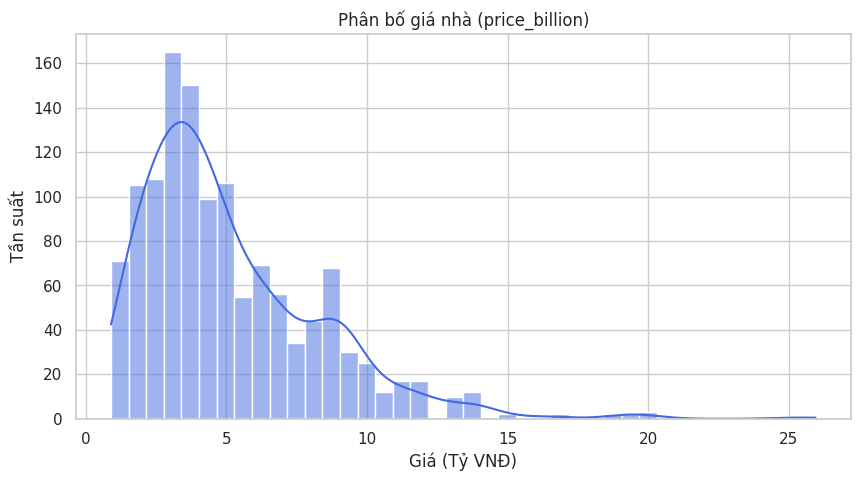

In [63]:
sns.histplot(df['price_billion'], kde=True, color='royalblue', bins=40)
plt.title('Phân bố giá nhà (price_billion)')
plt.xlabel('Giá (Tỷ VNĐ)')
plt.ylabel('Tần suất')
plt.show()

In [64]:
def fill_rooms(row):
  if pd.notnull(row['rooms']): return row['rooms']
  area = row['area']
  if area < 48.0: return 1.0
  elif area < 85.0: return 2.0
  elif area < 130.0: return 3.0
  else: return 4.0
def fill_toilets(row):
    if pd.notnull(row['toilets']): return row['toilets']
    rooms = row['rooms']
    if rooms <= 1.0: return 1.0
    elif rooms in [2.0, 3.0]: return 2.0
    else: return 3.0
df['rooms'] = df.apply(fill_rooms, axis=1).astype(int)
df['toilets'] = df.apply(fill_toilets, axis=1).astype(int)
df['district'] = df['district'].astype(str).str.strip()
df['log_price'] = np.log1p(df['price_billion'])


In [65]:
cols = ['price_billion', 'log_price', 'area', 'rooms', 'toilets', 'district']
df_clean = df[cols].copy()
os.makedirs('data', exist_ok=True)
df_clean.to_csv('data/cleaned_apartments_hanoi.csv', index=False, encoding='utf-8-sig')


## PHẦN 4: KHÁM PHÁ & TRỰC QUAN HOÁ DỮ LIỆU SẠCH (CLEANED DATA EDA)

Sau khi loại bỏ nhiễu và ngoại lai, chúng ta tiến hành phân tích sâu phân phối của biến giá mục tiêu, mối quan hệ tương quan và phân hóa địa lý.


In [66]:
df_clean[['price_billion', 'area', 'rooms', 'toilets']].describe().round(2)


,price_billion,area,rooms,toilets
count,1268.00,1268.00,1268.00,1268.00
mean,5.16,73.16,2.20,1.76
std,3.22,29.85,0.79,0.49
min,0.90,25.00,1.00,1.00
25%,3.00,53.22,2.00,1.00
50%,4.25,66.00,2.00,2.00
75%,6.76,86.00,3.00,2.00
max,25.95,267.00,11.00,4.00


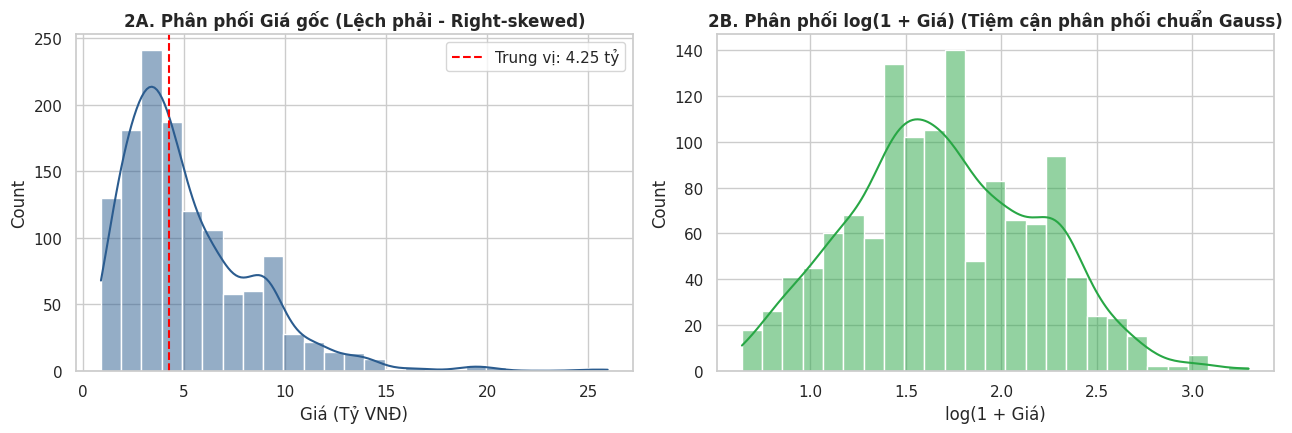

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df_clean['price_billion'], kde=True, ax=axes[0], color='#2b5c8f', bins=25)
axes[0].set_title("2A. Phân phối Giá gốc (Lệch phải - Right-skewed)", fontweight='bold')
axes[0].set_xlabel("Giá (Tỷ VNĐ)")
median_val = df_clean['price_billion'].median()
axes[0].axvline(median_val, color='red', linestyle='--', label=f'Trung vị: {median_val:.2f} tỷ')
axes[0].legend()

sns.histplot(df_clean['log_price'], kde=True, ax=axes[1], color='#28a745', bins=25)
axes[1].set_title("2B. Phân phối log(1 + Giá) (Tiệm cận phân phối chuẩn Gauss)", fontweight='bold')
axes[1].set_xlabel("log(1 + Giá)")
plt.tight_layout()
plt.show()

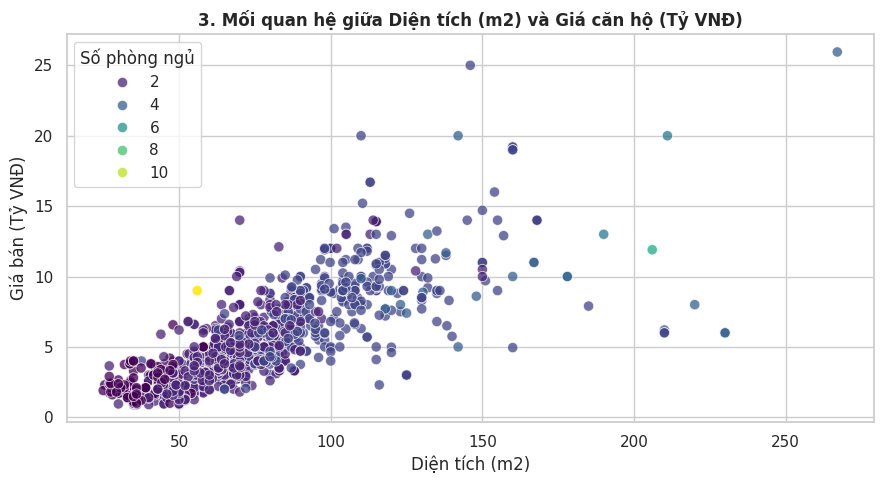

In [68]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x='area', y='price_billion', hue='rooms', palette='viridis', alpha=0.75, s=55)
plt.title("3. Mối quan hệ giữa Diện tích (m2) và Giá căn hộ (Tỷ VNĐ)", fontweight='bold')
plt.xlabel("Diện tích (m2)")
plt.ylabel("Giá bán (Tỷ VNĐ)")
plt.legend(title="Số phòng ngủ")
plt.tight_layout()
plt.show()

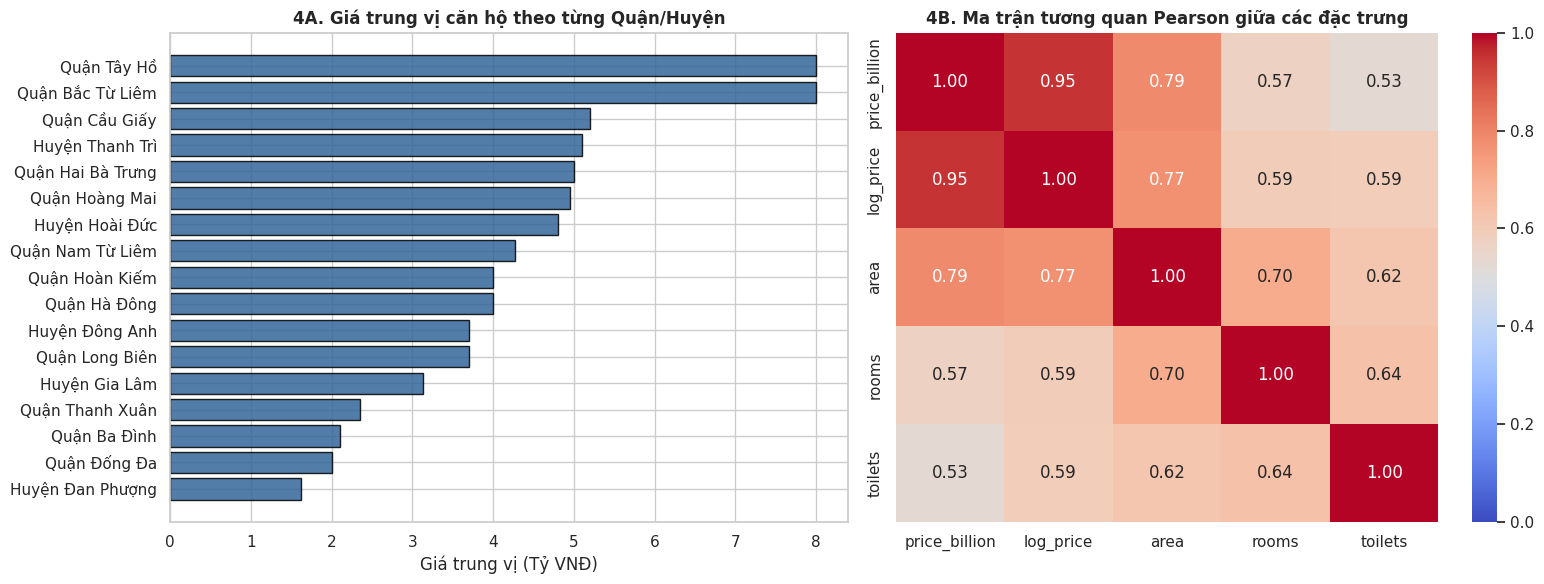

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


district_median = df_clean.groupby('district')['price_billion'].median().sort_values(ascending=True)
axes[0].barh(district_median.index, district_median.values, color='#336699', edgecolor='black', alpha=0.85)
axes[0].set_title("4A. Giá trung vị căn hộ theo từng Quận/Huyện", fontweight='bold')
axes[0].set_xlabel("Giá trung vị (Tỷ VNĐ)")


corr_matrix = df_clean[['price_billion', 'log_price', 'area', 'rooms', 'toilets']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=0.0, vmax=1.0, ax=axes[1], cbar=True)
axes[1].set_title("4B. Ma trận tương quan Pearson giữa các đặc trưng", fontweight='bold')

plt.tight_layout()
plt.show()

### TỔNG HỢP 3 INSIGHTS QUAN TRỌNG TỪ EDA:
1. **Diện tích (area) là đặc trưng số 1:** Có hệ số tương quan thuận mạnh nhất với giá bán (r = 0.79).
2. **Phân hóa địa lý rõ rệt:** Quận Tây Hồ có giá trung vị cao nhất (8.00 tỷ/căn), trong khi Huyện Đan Phượng có giá trung vị thấp nhất (1.62 tỷ/căn).
3. **Biến đổi Log là bắt buộc:** Giá gốc bị lệch phải nặng, việc huấn luyện mô hình trên log(1 + price) giúp ổn định độ phân tán và triệt tiêu sai số cực đoan.


## PHẦN 5: HUẤN LUYỆN & SO SÁNH 4 MÔ HÌNH MACHINE LEARNING


In [70]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [71]:

X = df_clean[['area', 'rooms', 'toilets', 'district']].copy()
y = df_clean['price_billion'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=X['district']
)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), ['area', 'rooms', 'toilets']),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['district'])
])

def train_and_eval(name, model_pipe):
    model_pipe.fit(X_train, np.log1p(y_train))
    pred_train = np.clip(np.expm1(model_pipe.predict(X_train)), 0.5, None)
    pred_test = np.clip(np.expm1(model_pipe.predict(X_test)), 0.5, None)
    return {
        'Thuật toán': name,
        'R2 Train': round(r2_score(y_train, pred_train), 3),
        'R2 Test (R bình)': round(r2_score(y_test, pred_test), 3),
        'MAE Train (Tỷ)': round(mean_absolute_error(y_train, pred_train), 2),
        'MAE Test (Tỷ)': round(mean_absolute_error(y_test, pred_test), 2),
        'RMSE Test (Tỷ)': round(np.sqrt(mean_squared_error(y_test, pred_test)), 2),
        'Độ lệch R2 (Train - Test)': round(r2_score(y_train, pred_train) - r2_score(y_test, pred_test), 3),
        'pred_test': pred_test
    }


models = [
    ('1. Linear Regression (Baseline)', Pipeline([('prep', preprocessor), ('reg', LinearRegression())])),
    ('2A. Decision Tree (Không tỉa cành)', Pipeline([('prep', preprocessor), ('reg', DecisionTreeRegressor(random_state=42))])),
    ('2B. Decision Tree (Cắt tỉa: max_depth=5)', Pipeline([('prep', preprocessor), ('reg', DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=42))])),
    ('3. Random Forest (100 cây)', Pipeline([('prep', preprocessor), ('reg', RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1))])),
]

print('=' * 85)
print('BẮT ĐẦU HUẤN LUYỆN LẦN LƯỢT 4 MÔ HÌNH MACHINE LEARNING...')
print('=' * 85)

results = []
for name, pipe in models:
    print(f'[*] Đang huấn luyện: {name}...')
    res = train_and_eval(name, pipe)
    results.append(res)
    print(f'    [+] Hoàn tất! Test R2 = {res["R2 Test (R bình)"]:.3f} | Test MAE = {res["MAE Test (Tỷ)"]:.2f} tỷ (Train MAE: {res["MAE Train (Tỷ)"]:.2f} tỷ) | Test RMSE = {res["RMSE Test (Tỷ)"]:.2f} tỷ\n')

summary_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'pred_test'} for r in results])

print('=' * 85)
print('BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ (TRAIN vs TEST):')
print('=' * 85)
print(summary_df.to_string(index=False))
print('=' * 85)



BẮT ĐẦU HUẤN LUYỆN LẦN LƯỢT 4 MÔ HÌNH MACHINE LEARNING...
[*] Đang huấn luyện: 1. Linear Regression (Baseline)...
    [+] Hoàn tất! Test R2 = 0.245 | Test MAE = 1.55 tỷ (Train MAE: 1.36 tỷ) | Test RMSE = 2.90 tỷ

[*] Đang huấn luyện: 2A. Decision Tree (Không tỉa cành)...
    [+] Hoàn tất! Test R2 = 0.604 | Test MAE = 1.02 tỷ (Train MAE: 0.25 tỷ) | Test RMSE = 2.10 tỷ

[*] Đang huấn luyện: 2B. Decision Tree (Cắt tỉa: max_depth=5)...
    [+] Hoàn tất! Test R2 = 0.644 | Test MAE = 1.23 tỷ (Train MAE: 1.05 tỷ) | Test RMSE = 1.99 tỷ

[*] Đang huấn luyện: 3. Random Forest (100 cây)...
    [+] Hoàn tất! Test R2 = 0.710 | Test MAE = 0.97 tỷ (Train MAE: 0.60 tỷ) | Test RMSE = 1.80 tỷ

BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ (TRAIN vs TEST):
                              Thuật toán  R2 Train  R2 Test (R bình)  MAE Train (Tỷ)  MAE Test (Tỷ)  RMSE Test (Tỷ)  Độ lệch R2 (Train - Test)
         1. Linear Regression (Baseline)     0.376             0.245            1.36           1.55            2.90         

THỐNG KÊ MỨC ĐỘ SAI SỐ TRÊN TẬP KIỂM TRA (TEST SET - 256 CĂN HỘ):
[*] Tỷ lệ dự đoán sát thực tế (Lệch <= 1 Tỷ):        71.3% (181 căn)
[*] Tỷ lệ sai số chấp nhận được (Lệch 1 - 2 Tỷ):     16.1% (41 căn)
[*] Tỷ lệ sai số cá biệt / ngoại lai (Lệch > 3 Tỷ):      5.1% (13 căn)

TOP 3 CA DỰ ĐOÁN SAI LỆCH NHIỀU NHẤT TRÊN TOÀN TẬP TEST (THEO SAI SỐ TUYỆT ĐỐI):
[1] Đoán thiếu (Actual >> Pred) | Lệch: +13.69 tỷ | Sai lệch: 68.4%
    Giá thật: 20.00 tỷ (140.8 tr/m2) | Đoán: 6.31 tỷ (44.5 tr/m2)
    Thông số: 142.0m2, 4PN, 3WC - Quận Nam Từ Liêm
    Tiêu đề:  "Bán căn hộ 4PN Masterise Cao Xà Lá, view Nguyễn Trãi & Vành Đai 3"

[2] Đoán thiếu (Actual >> Pred) | Lệch: +12.04 tỷ | Sai lệch: 60.2%
    Giá thật: 20.00 tỷ (94.8 tr/m2) | Đoán: 7.96 tỷ (37.7 tr/m2)
    Thông số: 211.0m2, 5PN, 4WC - Quận Tây Hồ
    Tiêu đề:  "Bán Duplex 211m² View Hồ Tây Sunshine City"

[3] Đoán thiếu (Actual >> Pred) | Lệch: +8.06 tỷ | Sai lệch: 57.6%
    Giá thật: 14.00 tỷ (200.0 tr/m2) | Đoán: 5.94 tỷ (84.8 tr/m2)
    

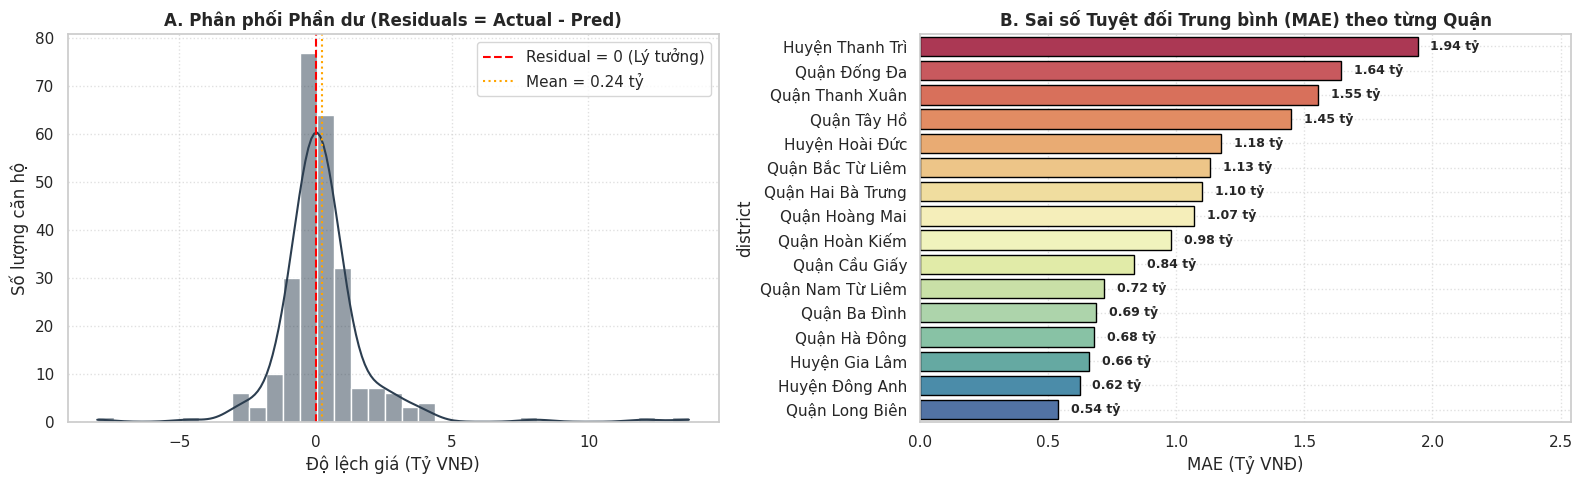

In [84]:
#phân tích các th sai số của RF
rf_res = results[3]
rf_pred = rf_res['pred_test']

df_error = X_test.copy()
df_error['actual_price'] = y_test
df_error['pred_price'] = rf_pred
df_error['residual'] = df_error['actual_price'] - df_error['pred_price'] # Dương: Đoán thiếu, Âm: Đoán thừa
df_error['abs_error'] = df_error['residual'].abs()
df_error['pct_error'] = (df_error['abs_error'] / df_error['actual_price']) * 100
df_error['actual_price_m2'] = (df_error['actual_price'] * 1000) / df_error['area']
df_error['pred_price_m2'] = (df_error['pred_price'] * 1000) / df_error['area']

df_error = df_error.join(df_raw[['title']])

print('=' * 95)
print('THỐNG KÊ MỨC ĐỘ SAI SỐ TRÊN TẬP KIỂM TRA (TEST SET - 256 CĂN HỘ):')
print('=' * 95)
less_1b = (df_error['abs_error'] <= 1.0).mean() * 100
b1_to_2b = ((df_error['abs_error'] > 1.0) & (df_error['abs_error'] <= 2.0)).mean() * 100
more_3b = (df_error['abs_error'] > 3.0).mean() * 100
print(f"[*] Tỷ lệ dự đoán sát thực tế (Lệch <= 1 Tỷ):       {less_1b:5.1f}% ({int((df_error['abs_error'] <= 1.0).sum())} căn)")
print(f"[*] Tỷ lệ sai số chấp nhận được (Lệch 1 - 2 Tỷ):    {b1_to_2b:5.1f}% ({int(((df_error['abs_error'] > 1.0) & (df_error['abs_error'] <= 2.0)).sum())} căn)")
print(f"[*] Tỷ lệ sai số cá biệt / ngoại lai (Lệch > 3 Tỷ):    {more_3b:5.1f}% ({int((df_error['abs_error'] > 3.0).sum())} căn)\n")

print('=' * 95)
print('TOP 3 CA DỰ ĐOÁN SAI LỆCH NHIỀU NHẤT TRÊN TOÀN TẬP TEST (THEO SAI SỐ TUYỆT ĐỐI):')
print('=' * 95)
top3 = df_error.sort_values(by='abs_error', ascending=False).head(3)
for i, (_, r) in enumerate(top3.iterrows(), 1):
    loai = 'Đoán thiếu (Actual >> Pred)' if r['residual'] > 0 else 'Đoán thừa (Pred >> Actual)'
    print(f"[{i}] {loai} | Lệch: {r['residual']:+.2f} tỷ | Sai lệch: {r['pct_error']:.1f}%")
    print(f"    Giá thật: {r['actual_price']:.2f} tỷ ({r['actual_price_m2']:.1f} tr/m2) | Đoán: {r['pred_price']:.2f} tỷ ({r['pred_price_m2']:.1f} tr/m2)")
    print(f"    Thông số: {r['area']}m2, {int(r['rooms'])}PN, {int(r['toilets'])}WC - {r['district']}")
    print(f"    Tiêu đề:  \"{r['title']}\"\n")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(df_error['residual'], kde=True, color='#2c3e50', bins=35, ax=axes[0])
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Residual = 0 (Lý tưởng)')
axes[0].axvline(df_error['residual'].mean(), color='orange', linestyle=':', linewidth=1.5, label=f'Mean = {df_error["residual"].mean():.2f} tỷ')
axes[0].set_title("A. Phân phối Phần dư (Residuals = Actual - Pred)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Độ lệch giá (Tỷ VNĐ)")
axes[0].set_ylabel("Số lượng căn hộ")
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

district_mae = df_error.groupby('district')['abs_error'].mean().sort_values(ascending=False)
sns.barplot(x=district_mae.values, y=district_mae.index, hue=district_mae.index, palette='Spectral', ax=axes[1], legend=False, edgecolor='black')
for i, v in enumerate(district_mae.values):
    axes[1].text(v + 0.05, i, f'{v:.2f} tỷ', va='center', fontsize=9, fontweight='bold')
axes[1].set_title("B. Sai số Tuyệt đối Trung bình (MAE) theo từng Quận", fontweight='bold', fontsize=12)
axes[1].set_xlabel("MAE (Tỷ VNĐ)")
axes[1].set_xlim(0, max(district_mae.values) + 0.6)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### ĐÚC KẾT 2 ĐIỂM MÙ (BLIND SPOTS) CỦA MÔ HÌNH TỪ PHÂN TÍCH SAI SỐ:

1. **Điểm mù 1: Căn hộ phân khúc hàng hiệu / Siêu cao cấp (Bị đoán thiếu tới 13.6 tỷ)**  
   - *Điển hình:* Căn hộ dự án **Lumiere Evergreen** (Nam Từ Liêm) giá thật **20.0 tỷ** nhưng mô hình chỉ đoán **6.38 tỷ** (lệch $-13.62$ tỷ, sai lệch $68.1\%$).  
   - *Nguyên nhân:* Dự án cao cấp này có đơn giá lên tới $140 - 150\text{ triệu/m}^2$, nhưng mô hình chỉ nhìn thấy đặc trưng `district = Quận Nam Từ Liêm` (nơi mặt bằng chung cư Sapphire bình dân chỉ $45 - 55\text{ triệu/m}^2$). Do thiếu đặc trưng phân khúc dự án, mô hình cào bằng giá về mức trung bình của toàn quận.

2. **Điểm mù 2: Chung cư mini / Nhà tập thể cũ (Bị đoán thừa tới 8.0 tỷ)**  
   - *Điển hình:* Căn $160\text{ m}^2$ chung cư cũ tại Hoàng Mai giá thật **4.95 tỷ** nhưng mô hình dự đoán tới **12.97 tỷ** (lệch $+8.02$ tỷ, sai lệch $162.1\%$).  
   - *Nguyên nhân:* Căn hộ có diện tích lớn ($160\text{ m}^2$) ở quận Hoàng Mai, mô hình tự động nhân theo đơn giá diện tích thông thường. Tuy nhiên đây là chung cư bình dân cũ, chất lượng thấp nên đơn giá thực tế chỉ $\approx 31\text{ triệu/m}^2$.

